In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

In [ ]:
# Cargar dataset de Anscombe quintet
url = 'https://raw.githubusercontent.com/Carl-McBride-Ellis/datasets_public/refs/heads/main/Anscombe_quintet_data.csv'
df = pd.read_csv(url).sort_values(by='x1235', ascending=True)

# Seleccionamos el set 2 (que tiene una relación más curva)
df["x"] = df["x1235"]
df["y"] = df["y2"]

df.head(10)

,x1235,y1,y2,y3,y5,x4,y4,x,y
7,4.0,4.26,3.10,5.39,6.03,19.0,12.50,4.0,3.10
10,5.0,5.68,4.74,5.73,5.92,8.0,6.89,5.0,4.74
6,6.0,7.24,6.13,6.08,5.80,8.0,5.25,6.0,6.13
9,7.0,4.82,7.26,6.42,5.68,8.0,7.91,7.0,7.26
1,8.0,6.95,8.14,6.77,5.56,8.0,5.76,8.0,8.14
3,9.0,8.81,8.77,7.11,5.45,8.0,8.84,9.0,8.77
0,10.0,8.04,9.14,7.46,9.82,8.0,6.58,10.0,9.14
4,11.0,8.33,9.26,7.81,9.72,8.0,8.47,11.0,9.26
8,12.0,10.84,9.13,8.15,9.61,8.0,5.56,12.0,9.13
2,13.0,7.58,8.74,12.74,9.51,8.0,7.71,13.0,8.74


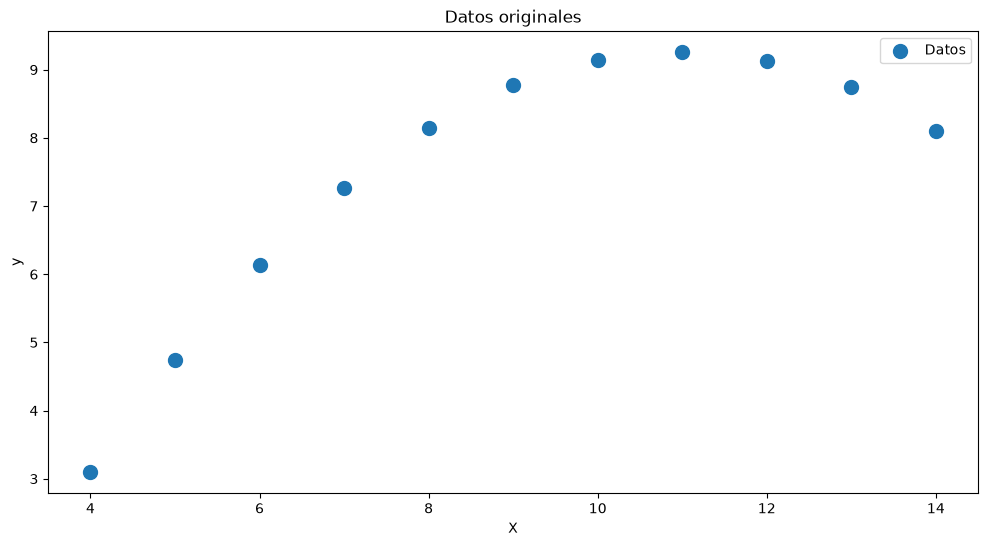

In [45]:
# Visualizamos los datos reales
plt.figure(figsize=(12, 6))
plt.scatter(df["x"], df["y"], s=100, label="Datos")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Datos originales")
plt.legend()
plt.show()

In [53]:
# Definir variables
X = sm.add_constant(df["x"])
y = df["y"]

# Ajustar el modelo lineal simple
modelo_lineal = LinearRegression().fit(X, y)

# Calcular predicciones
df["y_pred"] = modelo_lineal.predict(X)

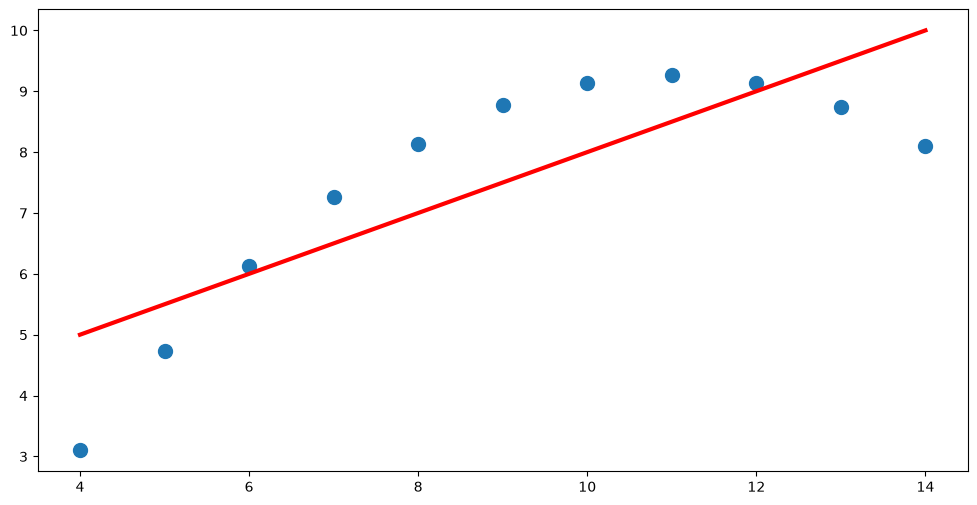

In [51]:
# Visualizamos los datos y la recta ajustada
plt.figure(figsize=(12, 6))

plt.scatter(df["x"], df["y"], s=100, label="Datos")
plt.plot(df["x"], df["y_pred"], color="red", lw=3, label="Ajuste lineal")

[[  4.  16.]
 [  5.  25.]
 [  6.  36.]
 [  7.  49.]
 [  8.  64.]
 [  9.  81.]
 [ 10. 100.]
 [ 11. 121.]
 [ 12. 144.]
 [ 13. 169.]
 [ 14. 196.]]
beta_0 -5.9957342657342885
beta_1 2.7808391608391654
beta_2 -0.1267132867132869


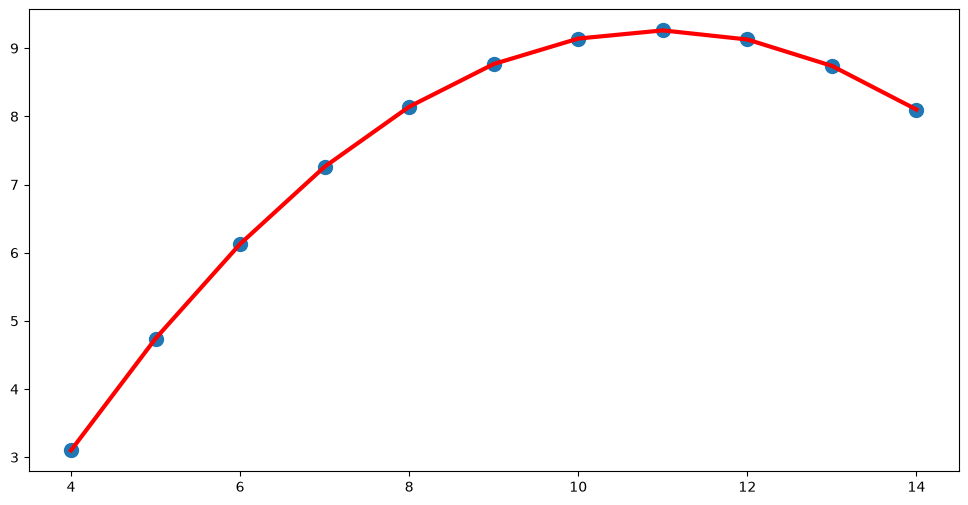

In [ ]:
# Generar las nuevas características polinómicas (x y x^2)
# Creamos un objeto transformador
poly = PolynomialFeatures(degree=2, include_bias=False)
# En X_poly guardamos la commna x y la columna de cuadrados de x
X_poly = poly.fit_transform(df[["x"]]) # crea columnas: [x, x^2]
print(X_poly)

# Ajuste del modelo lineal sobre estas nuevas features
modelo_poly2 = LinearRegression().fit(X_poly, df["y"])

# Predicciones
df["y_pred_poly2"] = modelo_poly2.predict(X_poly)

# Visualización
fig = plt.figure(figsize=(12,6))

# Puntos de datos reales
plt.scatter(df["x"], df["y"], s=100, label="Datos")

# Curva ajustada (ordenada por x para que la curva salga suave)
plt.plot(df["x"], df["y_pred_poly2"], color="red", lw=3, label="Ajuste lineal")

# Coeficientes
print("beta_0", modelo_poly2.intercept_)
print("beta_1", modelo_poly2.coef_[0])
print("beta_2", modelo_poly2.coef_[1])